# Fitting an approximation to an unknown posterior

**Lecture 1 · KL divergence, variational inference and the ELBO**

This notebook follows the lecture: Bayes' rule for a tiny neural network, its intractable evidence and its posterior predictive (Section 0); what KL measures (1–2); fitting q (3); Monte Carlo (4); gradients through draws (5); the ELBO (6); a check with an answer key (7); and variational inference for the tiny network (8). It adapts the PML 2023 Gaussian → mixture → differentiable sampling → coin sequence. The lecture uses three short demonstrations, marked **Live demo**; the saved outputs let class continue without waiting for training.

All distributions use natural logarithms. `Normal(loc=μ, scale=σ)` takes a **standard deviation**. Mathematical notation is $\mathcal N(\mu,\sigma^2)$. We use $u$ for a generic unknown, $r$ for a coin's probability of heads, $\mathcal D$ for observed data and $\psi$ for free variational parameters.

Run all cells, in order, in a Python environment with PyTorch, NumPy and matplotlib. No dataset download, GPU, external training framework or local helper import is needed. This notebook writes its measured figures and full-precision fixtures into `figures/` and `data/`.

In [1]:
from pathlib import Path
import json, math, platform
import numpy as np
import torch
from torch import distributions as dist
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.manual_seed(20261020)
np.random.seed(20261020)
OUT = Path.cwd()
for folder in ["figures", "data", "qa"]:
    (OUT / folder).mkdir(exist_ok=True)

C = dict(p="#0F766E", q="#8B2CDE", data="#245EDB", noise="#AA4E08", loss="#BE123C")
plt.rcParams.update({
    "font.family": ["Avenir Next", "Arial", "DejaVu Sans", "sans-serif"],
    "font.size": 19, "axes.titlesize": 21,
    "axes.labelsize": 19, "xtick.labelsize": 17, "ytick.labelsize": 17,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "#FAFAFB", "axes.facecolor": "#FAFAFB",
    "svg.fonttype": "none", "lines.linewidth": 2.5,
})
fixtures = {"provenance": {
    "seed": 20261020, "dtype": "torch.float64", "torch": torch.__version__,
    "python": platform.python_version(), "numpy": np.__version__,
    "evidence": "computed locally; analytic, quadrature and Monte Carlo outputs labelled separately",
    "source_spine": "PML 2023 variational-inference.ipynb; corrected standalone implementation",
}}
def number(x): return float(x.detach()) if isinstance(x, torch.Tensor) else float(x)
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / "figures" / f"{name}.svg", bbox_inches="tight")
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
def normal_kl(q, p):
    return torch.log(p.scale/q.scale) + (q.scale.square() + (q.loc-p.loc).square())/(2*p.scale.square()) - .5
print("CPU; float64; PyTorch", torch.__version__, "· fixed seeds recorded per experiment")

CPU; float64; PyTorch 2.13.0 · fixed seeds recorded per experiment


## 0. Bayes' rule for a tiny neural network

Bayes' rule for model parameters $\theta$ and training data $\mathcal D$:

$$p(\theta\mid\mathcal D)=\frac{p(\mathcal D\mid\theta)\,p(\theta)}{p(\mathcal D)}.$$

The network has one input, two tanh hidden units and one output:

$$f_\theta(x)=v_1\tanh(w_1x+b_1)+v_2\tanh(w_2x+b_2)+c,\qquad\theta=(w_1,w_2,b_1,b_2,v_1,v_2,c)\in\mathbb R^7.$$

**Prior:** every parameter independently $\mathcal N(0,1)$. **Likelihood:** $y_i\mid x_i,\theta\sim\mathcal N\big(f_\theta(x_i),0.1^2\big)$, with the noise scale known. Seventeen training points, with a gap in the middle.

prior predictive sd at x = −2.5, 0, 2.5: [1.54, 1.33, 1.55]
theta A, the MAP: log p(D|θ) = 12.17, log p(θ) = -9.41
theta B, a prior draw: log p(D|θ) = -2157.52, log p(θ) = -9.89


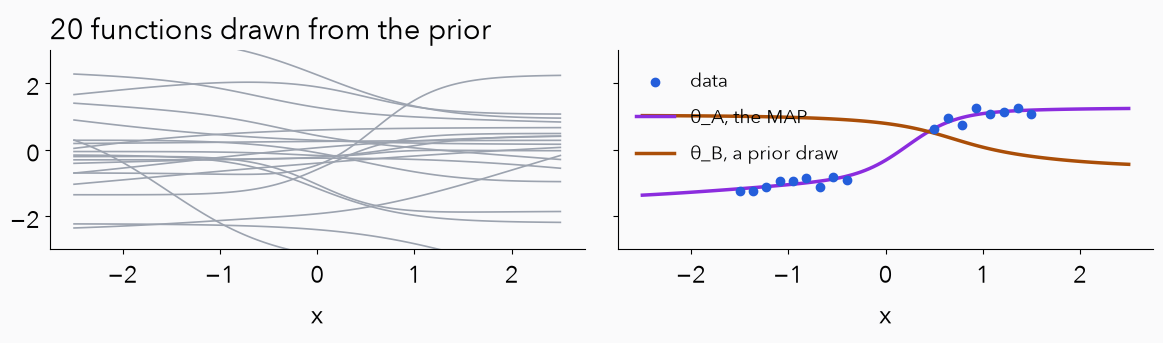

In [2]:
bnn_names = ["w1", "w2", "b1", "b2", "v1", "v2", "c"]
def net(theta, x):
    # theta [..., 7] and inputs x [N] give outputs [..., N]
    w, b, v, c = theta[..., 0:2], theta[..., 2:4], theta[..., 4:6], theta[..., 6:7]
    hidden = torch.tanh(w[..., None, :] * x[:, None] + b[..., None, :])
    return (hidden * v[..., None, :]).sum(-1) + c
torch.manual_seed(7)
x_train = torch.cat([torch.linspace(-1.5, -0.4, 9), torch.linspace(0.5, 1.5, 8)])
noise_sd = 0.1
y_train = 0.8 * torch.tanh(3 * x_train) + 0.3 * x_train + noise_sd * torch.randn(len(x_train))
theta_prior = dist.Normal(torch.zeros(7), torch.ones(7))
def bnn_log_lik(theta):
    return dist.Normal(net(theta, x_train), noise_sd).log_prob(y_train).sum(-1)
def bnn_log_prior(theta):
    return theta_prior.log_prob(theta).sum(-1)
def bnn_log_joint(theta):
    return bnn_log_lik(theta) + bnn_log_prior(theta)
# theta_A: the most probable parameters (MAP), best of ten restarts. theta_B: one draw from the prior.
best = None
for seed in range(10):
    torch.manual_seed(seed)
    th = torch.nn.Parameter(torch.randn(7))
    opt_map = torch.optim.Adam([th], lr=.05)
    for _ in range(2000):
        loss = -bnn_log_joint(th)
        opt_map.zero_grad(); loss.backward(); opt_map.step()
    if best is None or number(loss) < best[0]:
        best = (number(loss), th.detach().clone())
theta_A = best[1]
torch.manual_seed(11)
theta_B = theta_prior.sample()
def bnn_terms(theta):
    point = dist.Normal(net(theta, x_train), noise_sd).log_prob(y_train)
    return dict(theta=theta.tolist(), fitted=net(theta, x_train).tolist(), log_lik_points=point.tolist(),
                log_lik=number(point.sum()), log_prior_terms=theta_prior.log_prob(theta).tolist(),
                log_prior=number(bnn_log_prior(theta)), log_joint=number(bnn_log_joint(theta)))
x_grid = torch.linspace(-2.5, 2.5, 121)
torch.manual_seed(12)
prior_draws = theta_prior.sample((20,))
# The prior predictive: average over many prior draws, then add the observation noise
torch.manual_seed(15)
F_prior = net(theta_prior.sample((4000,)), x_grid)
prior_predictive = dict(draws=4000, mean=F_prior.mean(0).tolist(), sd_f=F_prior.std(0).tolist(),
                        sd=(F_prior.var(0) + noise_sd ** 2).sqrt().tolist())
fixtures["story"] = {"bnn": dict(names=bnn_names, x=x_train.tolist(), y=y_train.tolist(), noise_sd=noise_sd,
    prior=[0., 1.], data="y = 0.8 tanh(3x) + 0.3x + N(0, 0.1²) noise, seed 7", grid=x_grid.tolist(),
    theta_A=bnn_terms(theta_A), theta_B=bnn_terms(theta_B),
    f_A=net(theta_A, x_grid).tolist(), f_B=net(theta_B, x_grid).tolist(),
    prior_draws=net(prior_draws, x_grid).tolist(), prior_thetas=prior_draws.tolist(),
    prior_predictive=prior_predictive)}
print("prior predictive sd at x = −2.5, 0, 2.5:", [round(prior_predictive["sd"][i], 2) for i in (0, 60, 120)])
for name, th in [("A, the MAP", theta_A), ("B, a prior draw", theta_B)]:
    print(f"theta {name}: log p(D|θ) = {number(bnn_log_lik(th)):.2f}, log p(θ) = {number(bnn_log_prior(th)):.2f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for f_draw in net(prior_draws, x_grid):
    axes[0].plot(x_grid, f_draw, color="#9CA3AF", lw=1.2)
axes[0].set_title("20 functions drawn from the prior", loc="left")
axes[1].scatter(x_train, y_train, color=C["data"], zorder=3, label="data")
axes[1].plot(x_grid, net(theta_A, x_grid), color=C["q"], label="θ_A, the MAP")
axes[1].plot(x_grid, net(theta_B, x_grid), color=C["noise"], label="θ_B, a prior draw")
for ax in axes:
    ax.set(xlabel="x", ylim=(-3, 3))
axes[1].legend(frameon=False, fontsize=14)
savefig("bnn-prior-and-fits")

### The evidence: an integral over all seven parameters

$$p(\mathcal D)=\int_{\mathbb R^7}p(\mathcal D\mid\theta)\,p(\theta)\,d\theta.$$

The network is nonlinear in $\theta$, so there is no formula. A grid with 100 points per parameter needs $100^7=10^{14}$ evaluations. Monte Carlo from the prior averages $p(\mathcal D\mid\theta)$ over prior draws, but almost every draw explains the data terribly, so a few lucky draws carry the whole average.

1000 [-1092.95, -121.1, -23.37, -9.43, -2.57, -1.44, -1.4] · effective draws 77 · largest share 0.079
1001 [-879.09, -215.97, -16.38, -4.39, -0.68, -1.72, -1.41] · effective draws 93 · largest share 0.043
1002 [-1211.04, -44.28, -26.01, -6.24, -2.37, -1.59, -1.53] · effective draws 134 · largest share 0.035
1003 [-487.5, -100.7, -12.13, -2.54, -2.88, -1.2, -1.38] · effective draws 108 · largest share 0.035
log p(D) ≈ -1.43, the mean of the four 10-million-draw estimates


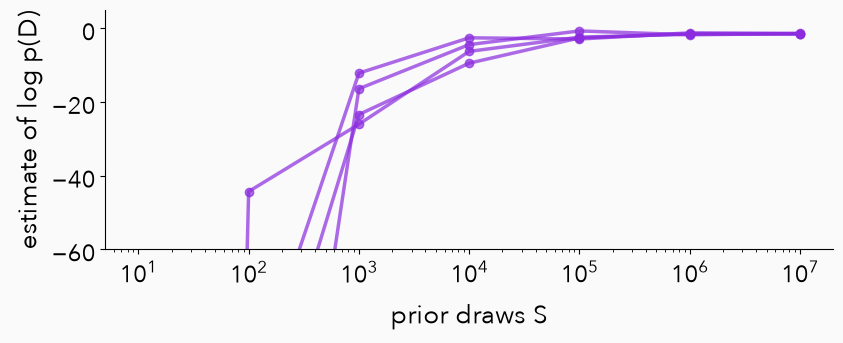

In [3]:
mc_sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000]
evidence_runs = []
for seed in range(4):
    torch.manual_seed(1000 + seed)
    ll = torch.cat([bnn_log_lik(theta_prior.sample((500_000,))) for _ in range(20)])
    weights = torch.exp(ll - ll.max())
    evidence_runs.append(dict(seed=1000 + seed,
        estimates=[number(torch.logsumexp(ll[:S], 0)) - math.log(S) for S in mc_sizes],
        effective_draws=number(weights.sum() ** 2 / (weights ** 2).sum()),
        largest_share=number(weights.max() / weights.sum())))
log_evidence_bnn = float(np.mean([r["estimates"][-1] for r in evidence_runs]))
fixtures["story"]["bnn"]["evidence"] = dict(sizes=mc_sizes, runs=evidence_runs, estimate=log_evidence_bnn,
    grid_points_per_parameter=100, parameters=7)
for r in evidence_runs:
    print(r["seed"], [round(v, 2) for v in r["estimates"]], "· effective draws",
          round(r["effective_draws"]), "· largest share", round(r["largest_share"], 3))
print(f"log p(D) ≈ {log_evidence_bnn:.2f}, the mean of the four 10-million-draw estimates")
fig, ax = plt.subplots(figsize=(8.8, 3.8))
for r in evidence_runs:
    ax.plot(mc_sizes, r["estimates"], marker="o", color=C["q"], alpha=.7)
ax.set(xscale="log", ylim=(-60, 5), xlabel="prior draws S", ylabel="estimate of log p(D)")
savefig("bnn-evidence-mc")

### What we want in the end: the posterior predictive

$$p(y^*\mid x^*,\mathcal D)=\int p(y^*\mid x^*,\theta)\,p(\theta\mid\mathcal D)\,d\theta.$$

Variational inference is today's method. Here we use Hamiltonian Monte Carlo, run long, only as a **reference**: it shows what the exact posterior predictive looks like, and later checks VI. Four chains of 2,000 samples after 500 warm-up steps, each started at the MAP.

acceptance [0.904, 0.904, 0.89, 0.903]
predictive sd at x = −2.5, 0, 2.5: [0.215, 0.162, 0.168]


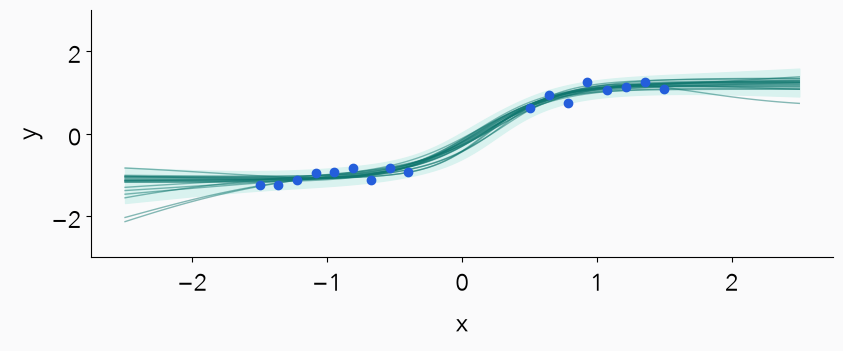

In [4]:
def hmc_chain(theta0, n_keep, n_warm, step_size, leapfrog, seed):
    torch.manual_seed(seed)
    def potential(t):
        t = t.clone().requires_grad_(True)
        U = -bnn_log_joint(t)
        grad, = torch.autograd.grad(U, t)
        return U.detach(), grad
    th, (U, grad) = theta0.clone(), potential(theta0)
    kept, accepted = [], 0
    for it in range(n_warm + n_keep):
        p0 = torch.randn(7)
        p_mom, t_new = p0 - .5 * step_size * grad, th.clone()
        for l in range(leapfrog):
            t_new = t_new + step_size * p_mom
            U_new, grad_new = potential(t_new)
            if l < leapfrog - 1:
                p_mom = p_mom - step_size * grad_new
        p_mom = p_mom - .5 * step_size * grad_new
        if torch.log(torch.rand(())) < (U + .5 * (p0 ** 2).sum()) - (U_new + .5 * (p_mom ** 2).sum()):
            th, U, grad = t_new, U_new, grad_new
            accepted += it >= n_warm
        if it >= n_warm:
            kept.append(th.clone())
    return torch.stack(kept), accepted / n_keep
chains = [hmc_chain(theta_A, 2000, 500, .02, 25, seed) for seed in (1, 2, 3, 4)]
hmc_samples = torch.cat([chain for chain, _ in chains])
F_post = net(hmc_samples, x_grid)
post_sd_f = F_post.std(0)
post_sd = (post_sd_f ** 2 + noise_sd ** 2).sqrt()
torch.manual_seed(13)
show = torch.randperm(len(hmc_samples))[:20]
fixtures["story"]["bnn"]["hmc"] = dict(chains=4, kept=2000, warmup=500, step_size=.02, leapfrog=25,
    acceptance=[rate for _, rate in chains], mean=F_post.mean(0).tolist(), sd_f=post_sd_f.tolist(),
    sd=post_sd.tolist(), draws=F_post[show].tolist())
print("acceptance", [round(rate, 3) for _, rate in chains])
print("predictive sd at x = −2.5, 0, 2.5:", [round(number(post_sd[i]), 3) for i in (0, 60, 120)])
fig, ax = plt.subplots(figsize=(8.8, 4))
m = F_post.mean(0)
ax.fill_between(x_grid, m - 2 * post_sd, m + 2 * post_sd, color="#D9F2EF")
for f_draw in F_post[show]:
    ax.plot(x_grid, f_draw, color=C["p"], lw=1, alpha=.5)
ax.scatter(x_train, y_train, color=C["data"], zorder=3)
ax.set(xlabel="x", ylabel="y", ylim=(-3, 3))
savefig("bnn-posterior-predictive")

### Three ways around an intractable posterior

On a two-bump target, $0.7\,\mathcal N(-2,1)+0.3\,\mathcal N(2,1)$:

- **Laplace**: find the highest peak and fit a Gaussian to its curvature.
- **MCMC**: a random walk whose visits follow the target (random-walk Metropolis).
- **Variational inference**: the Gaussian $q$ closest to the target in $\mathrm{KL}(q\,\|\,p)$, found by gradient descent.

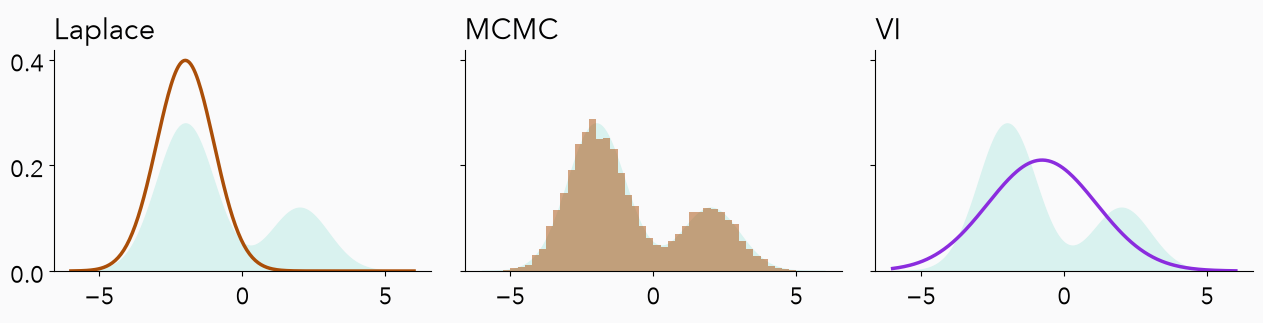

Laplace: [-1.9994236770045335, 1.001154476066346] · MCMC mean -0.801 acceptance 0.6069 · VI: [-0.775641838128022, 1.900747471367499]


In [5]:
three_target = dist.MixtureSameFamily(dist.Categorical(probs=torch.tensor([.7, .3])),
    dist.Normal(torch.tensor([-2., 2.]), torch.tensor([1., 1.])))
def grid_kl(a, b, grid):
    # KL(a || b) by the trapezoid rule on a fixed grid
    la, lb = a.log_prob(grid), b.log_prob(grid)
    return torch.trapezoid(la.exp() * (la - lb), grid)
# Laplace: the highest peak, then the curvature there
peak = torch.tensor(-1.0, requires_grad=True)
peak_opt = torch.optim.Adam([peak], lr=.05)
for _ in range(2000):
    loss = -three_target.log_prob(peak)
    peak_opt.zero_grad(); loss.backward(); peak_opt.step()
mode = peak.detach()
curvature = torch.autograd.functional.hessian(lambda t: three_target.log_prob(t), mode)
laplace = dist.Normal(mode, (-curvature).rsqrt())
# MCMC: random-walk Metropolis
torch.manual_seed(7)
state = torch.tensor(0.); state_lp = three_target.log_prob(state); chain = []; accepted = 0
for _ in range(20_000):
    proposal = state + 2.0 * torch.randn(())
    proposal_lp = three_target.log_prob(proposal)
    if torch.log(torch.rand(())) < proposal_lp - state_lp:
        state, state_lp, accepted = proposal, proposal_lp, accepted + 1
    chain.append(number(state))
chain = np.array(chain)
# VI: minimise KL(q || p) on a grid
grid3 = torch.linspace(-8, 8, 2001)
m3 = torch.nn.Parameter(torch.tensor(-.5)); rho3 = torch.nn.Parameter(torch.tensor(0.))
opt3 = torch.optim.Adam([m3, rho3], lr=.05)
for _ in range(600):
    loss = grid_kl(dist.Normal(m3, rho3.exp()), three_target, grid3)
    opt3.zero_grad(); loss.backward(); opt3.step()
vi3 = dist.Normal(m3.detach(), rho3.detach().exp())
x3 = torch.linspace(-6, 6, 241)
hist, edges = np.histogram(chain, bins=np.linspace(-6, 6, 49), density=True)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, title in zip(axes, ["Laplace", "MCMC", "VI"]):
    ax.fill_between(x3, 0, three_target.log_prob(x3).exp(), color="#D9F2EF")
    ax.set_title(title, loc="left")
axes[0].plot(x3, laplace.log_prob(x3).exp(), color=C["noise"])
axes[1].hist(chain, bins=edges, density=True, color=C["noise"], alpha=.5)
axes[2].plot(x3, vi3.log_prob(x3).exp(), color=C["q"])
savefig("three-ways")
fixtures["story"]["three"] = dict(weights=[.7, .3], means=[-2., 2.], scales=[1., 1.],
    laplace=[number(laplace.loc), number(laplace.scale)],
    mcmc=dict(steps=20_000, step_size=2.0, seed=7, acceptance=accepted / 20_000,
              mean=float(chain.mean()), hist=hist.tolist(), edges=edges.tolist()),
    vi=[number(vi3.loc), number(vi3.scale)], true_mean=.7 * -2 + .3 * 2,
    plot=dict(x=x3.tolist(), p=three_target.log_prob(x3).exp().tolist(),
              laplace=laplace.log_prob(x3).exp().tolist(), vi=vi3.log_prob(x3).exp().tolist()))
print("Laplace:", fixtures["story"]["three"]["laplace"], "· MCMC mean", round(float(chain.mean()), 3),
      "acceptance", accepted / 20_000, "· VI:", fixtures["story"]["three"]["vi"])

## 1. What does “close” mean? Build the KL divergence

**A favourite-fruit survey.** Year 1 is the reference $q$: 50% apple, 40% banana, 10% clementine. Year 2 is $p$: 50%, 10%, 40%. One number for how much year 2 differs, relative to year 1:

1. Compare by **ratios**, $p/q$: $1, \tfrac14, 4$.
2. Take the **log**, so that a fourfold rise and a fourfold fall cancel: $0, -1.386, 1.386$.
3. **Weight** each fruit by how common it is in $p$, and add: $\mathrm{KL}(p\|q)=\sum_x p(x)\log\frac{p(x)}{q(x)}$.

The same number has a coding meaning: the extra average message length (in bits, with $\log_2$) of using a code built for the wrong distribution. And it is the rate at which data separate two hypotheses.

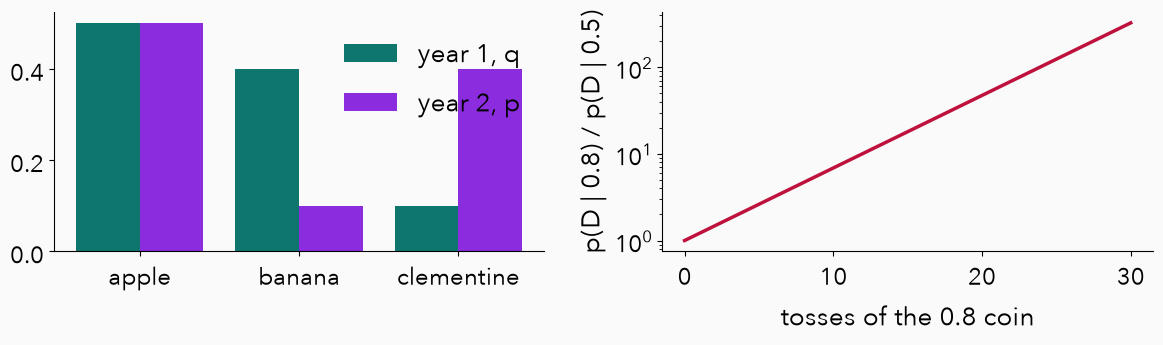

Fruit: KL(p||q) = 0.4159 nats (library 0.4159)
Weather: H(p) = 1.50 bits, H(p, q) = 1.75 bits, KL = 0.25 bits
Coins: KL(0.8 || 0.5) = 0.1927, reverse 0.2231; e^(10 KL) = 6.9, e^(30 KL) = 325; simulated mean log ratio after 30 = 5.780 (30 KL = 5.782)


In [6]:
fruit_names = ["apple", "banana", "clementine"]
fruit_q = np.array([.5, .4, .1])
fruit_p = np.array([.5, .1, .4])
fruit_ratio = fruit_p / fruit_q
fruit_terms = fruit_p * np.log(fruit_ratio)
fruit_kl = float(fruit_terms.sum())
library = number(dist.kl_divergence(dist.Categorical(probs=torch.tensor(fruit_p)),
                                    dist.Categorical(probs=torch.tensor(fruit_q))))
assert abs(fruit_kl - library) < 1e-12
weather_p = np.array([.5, .25, .25])
weather_q = np.array([.25, .5, .25])
entropy_bits = float(-(weather_p * np.log2(weather_p)).sum())
cross_entropy_bits = float(-(weather_p * np.log2(weather_q)).sum())
assert abs((cross_entropy_bits - entropy_bits) - float((weather_p * np.log2(weather_p / weather_q)).sum())) < 1e-12
coin_08, coin_05 = dist.Bernoulli(torch.tensor(.8)), dist.Bernoulli(torch.tensor(.5))
kl_coin = number(dist.kl_divergence(coin_08, coin_05))
kl_coin_reverse = number(dist.kl_divergence(coin_05, coin_08))
torch.manual_seed(5)
toss_sim = (torch.rand(20_000, 30) < .8).double()
llr = (toss_sim * math.log(.8 / .5) + (1 - toss_sim) * math.log(.2 / .5)).cumsum(1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
xs = np.arange(3)
axes[0].bar(xs - .2, fruit_q, .4, color=C["p"], label="year 1, q")
axes[0].bar(xs + .2, fruit_p, .4, color=C["q"], label="year 2, p")
axes[0].set_xticks(xs, fruit_names); axes[0].legend(frameon=False)
n = np.arange(31)
axes[1].semilogy(n, np.exp(n * kl_coin), color=C["loss"])
axes[1].set(xlabel="tosses of the 0.8 coin", ylabel="p(D | 0.8) / p(D | 0.5)")
savefig("kl-intuition")
fixtures["story"]["fruit"] = dict(names=fruit_names, q=fruit_q.tolist(), p=fruit_p.tolist(),
    ratio=fruit_ratio.tolist(), log_ratio=np.log(fruit_ratio).tolist(), terms=fruit_terms.tolist(),
    kl=fruit_kl, ratio_mean=float(fruit_ratio.mean()))
fixtures["story"]["bits"] = dict(p=weather_p.tolist(), q=weather_q.tolist(), entropy=entropy_bits,
    cross_entropy=cross_entropy_bits, kl=cross_entropy_bits - entropy_bits,
    names=["sunny", "cloudy", "rainy"], right_code=["0", "10", "11"], wrong_code=["10", "0", "11"])
fixtures["story"]["coinkl"] = dict(kl=kl_coin, reverse=kl_coin_reverse,
    x10=math.exp(10 * kl_coin), x30=math.exp(30 * kl_coin),
    simulated_mean_llr_30=float(llr[:, -1].mean()), simulated_sequences=20_000, simulation_seed=5)
print(f"Fruit: KL(p||q) = {fruit_kl:.4f} nats (library {library:.4f})")
print(f"Weather: H(p) = {entropy_bits:.2f} bits, H(p, q) = {cross_entropy_bits:.2f} bits, "
      f"KL = {cross_entropy_bits - entropy_bits:.2f} bits")
print(f"Coins: KL(0.8 || 0.5) = {kl_coin:.4f}, reverse {kl_coin_reverse:.4f}; "
      f"e^(10 KL) = {math.exp(10 * kl_coin):.1f}, e^(30 KL) = {math.exp(30 * kl_coin):.0f}; "
      f"simulated mean log ratio after 30 = {float(llr[:, -1].mean()):.3f} (30 KL = {30 * kl_coin:.3f})")

## 2. Which Gaussian is closer?

Fix $p=\mathcal N(1,4^2)$. Compare $q_1=\mathcal N(0,2^2)$ and $q_2=\mathcal N(1,3^2)$.

**Predict first:** compare their centres and widths. A visual judgement motivates a score; it does not define one.

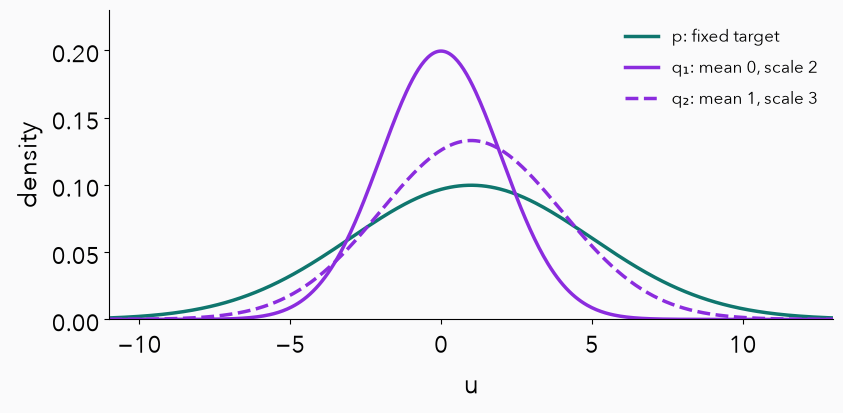

In [7]:
p = dist.Normal(torch.tensor(1.), torch.tensor(4.))
q1 = dist.Normal(torch.tensor(0.), torch.tensor(2.))
q2 = dist.Normal(torch.tensor(1.), torch.tensor(3.))
u = torch.linspace(-11, 13, 481)
fig, ax = plt.subplots(figsize=(8.8, 4.5))
for d, label, col, style in [(p, "p: fixed target", C["p"], "-"),
                            (q1, "q₁: mean 0, scale 2", C["q"], "-"),
                            (q2, "q₂: mean 1, scale 3", C["q"], "--")]:
    ax.plot(u, d.log_prob(u).exp(), label=label, color=col, ls=style)
ax.set(xlim=(-11,13), ylim=(0,.23), xlabel="u", ylabel="density")
ax.legend(frameon=False, fontsize=12)
savefig("gaussian-candidates")

### A local log ratio, then an average

$\log q(u)-\log p(u)$ compares the two densities at one location. The first argument in

$$\mathrm{KL}(q\|p)=\mathbb E_{u\sim q}\left[\log q(u)-\log p(u)\right]$$

tells us which distribution weights the average. A local log ratio can be negative. The exact KL is nonnegative, under the usual support and finiteness conditions.

For two Normals:

$$\mathrm{KL}(q\|p)=\log\frac{s}{\sigma}+
\frac{\sigma^2+(\mu-m)^2}{2s^2}-\frac12.$$

The key moment is $\mathbb E_q[(u-m)^2]=\sigma^2+(\mu-m)^2$. The cross-term vanishes because $\mathbb E_q[u-\mu]=0$.

In [8]:
normal_values = {}
for name, q in [("q1", q1), ("q2", q2)]:
    manual = normal_kl(q,p)
    library = dist.kl_divergence(q,p)
    reverse = dist.kl_divergence(p,q)
    assert torch.allclose(manual, library, atol=1e-12, rtol=0)
    check_grid=torch.linspace(number(q.loc-12*q.scale),number(q.loc+12*q.scale),100001)
    integral=torch.trapezoid(q.log_prob(check_grid).exp()*
                            (q.log_prob(check_grid)-p.log_prob(check_grid)),check_grid)
    assert abs(number(manual-integral))<1e-9
    normal_values[name] = dict(mu=number(q.loc), sigma=number(q.scale),
                             kl=number(manual), reverse_kl=number(reverse),quadrature=number(integral))
    print(f"{name}: KL(q||p) = {manual:.9f}; KL(p||q) = {reverse:.9f} nats")
assert dist.kl_divergence(p,p) == 0
print("Matched distributions: KL(p||p) =", number(dist.kl_divergence(p,p)))
fixtures["normal"] = {"target": {"mu":1., "sigma":4.}, "candidates":normal_values}

q1: KL(q||p) = 0.349397181; KL(p||q) = 0.931852819 nats
q2: KL(q||p) = 0.068932072; KL(p||q) = 0.101206816 nats
Matched distributions: KL(p||p) = 0.0


### Which direction? Fit one Gaussian to two bumps

Target $p=0.7\,\mathcal N(-2,w^2)+0.3\,\mathcal N(2,w^2)$. Fit a Gaussian $q$ by gradient descent on each direction of the KL, computed on a grid. $\mathrm{KL}(p\|q)$ averages under $p$, so $q$ must cover both bumps. $\mathrm{KL}(q\|p)$ averages under $q$, so mass in the gap is expensive and $q$ settles on one bump; which one depends on where it starts.

bump width 1.0: fwd: N(-0.80, 2.09^2), KL 0.180; revl: N(-0.78, 1.90^2), KL 0.237; revr: N(-0.78, 1.90^2), KL 0.237


bump width 0.5: fwd: N(-0.80, 1.90^2), KL 0.724; revl: N(-2.00, 0.50^2), KL 0.357; revr: N(2.00, 0.50^2), KL 1.204


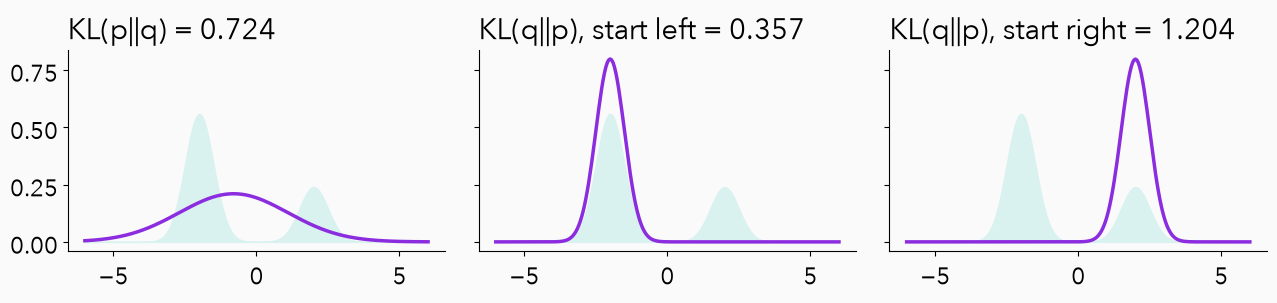

In [9]:
def bump_mixture(width):
    return dist.MixtureSameFamily(dist.Categorical(probs=torch.tensor([.7, .3])),
        dist.Normal(torch.tensor([-2., 2.]), torch.tensor([width, width])))
grid_fr = torch.linspace(-8, 8, 2001)
x_fr = torch.linspace(-6, 6, 241)
def fit_direction(target, direction, start, steps=300, lr=.05, every=2):
    m = torch.nn.Parameter(torch.tensor(start[0]))
    rho = torch.nn.Parameter(torch.tensor(math.log(start[1])))
    opt = torch.optim.Adam([m, rho], lr=lr); frames = []
    for step in range(steps + 1):
        q = dist.Normal(m, rho.exp())
        loss = grid_kl(q, target, grid_fr) if direction == "reverse" else grid_kl(target, q, grid_fr)
        if step % every == 0:
            frames.append([step, number(m), number(rho.exp()), number(loss)])
        if step == steps:
            break
        opt.zero_grad(); loss.backward(); opt.step()
    return frames
fwdrev = {"x": x_fr.tolist(), "start": {"fwd": [.5, .6], "revl": [-.5, .6], "revr": [.5, .6]}, "steps": 300, "lr": .05}
for width in [1.0, 0.5]:
    target = bump_mixture(width)
    runs = {"fwd": fit_direction(target, "forward", (.5, .6)),
            "revl": fit_direction(target, "reverse", (-.5, .6)),
            "revr": fit_direction(target, "reverse", (.5, .6))}
    fwdrev[str(width)] = dict(p=target.log_prob(x_fr).exp().tolist(), **runs)
    print(f"bump width {width}: " + "; ".join(
        f"{k}: N({v[-1][1]:.2f}, {v[-1][2]:.2f}^2), KL {v[-1][3]:.3f}" for k, v in runs.items()))
fixtures["story"]["fwdrev"] = fwdrev
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
narrow = bump_mixture(.5)
for ax, key, title in zip(axes, ["fwd", "revl", "revr"], ["KL(p||q)", "KL(q||p), start left", "KL(q||p), start right"]):
    _, m_, s_, k_ = fwdrev["0.5"][key][-1]
    ax.fill_between(x_fr, 0, narrow.log_prob(x_fr).exp(), color="#D9F2EF")
    ax.plot(x_fr, dist.Normal(m_, s_).log_prob(x_fr).exp(), color=C["q"])
    ax.set_title(f"{title} = {k_:.3f}", loc="left")
savefig("forward-reverse")

## 3. Make q move

**Live demo 1 · about 3 minutes.** Hold $\sigma=2$ fixed and start at $\mu=0$.

$$\frac{\partial L}{\partial\mu}=\frac{\mu-1}{16},\qquad
\mu^+=\mu-\eta\frac{\partial L}{\partial\mu}.$$

With chosen $\eta=4$, predict the new mean before running the cell. A negative derivative means gradient descent moves the mean right.

In [10]:
mu = torch.tensor(0., requires_grad=True)
q = dist.Normal(mu, torch.tensor(2.))
before = dist.kl_divergence(q,p)
before.backward()
gradient = number(mu.grad)
eta = 4.
with torch.no_grad():
    mu_after = mu - eta*mu.grad
after = dist.kl_divergence(dist.Normal(mu_after, torch.tensor(2.)), p)
h = 1e-5
fd = (normal_kl(dist.Normal(mu.detach()+h,2.),p)
      - normal_kl(dist.Normal(mu.detach()-h,2.),p))/(2*h)
assert abs(gradient-number(fd)) < 1e-9
assert number(after) < number(before)
fixtures["normal"]["one_step"] = dict(mu_before=0., sigma=2., eta=eta,
    gradient=gradient, mu_after=number(mu_after), kl_before=number(before),
    kl_after=number(after), finite_difference=number(fd),
    fixed_scale_best_kl=number(dist.kl_divergence(dist.Normal(1.,2.),p)))
print(fixtures["normal"]["one_step"])

{'mu_before': 0.0, 'sigma': 2.0, 'eta': 4.0, 'gradient': -0.0625, 'mu_after': 0.25, 'kl_before': 0.3493971805599453, 'kl_after': 0.3357253055599453, 'finite_difference': -0.06250000000318501, 'fixed_scale_best_kl': 0.3181471805599453}


Moving only the mean cannot match a width of 4. Its best possible KL is still positive.

To learn both parameters, optimise unconstrained $\mu,\rho$ and construct $\sigma=\exp(\rho)>0$. Here $\rho$ means **log standard deviation**, not log variance. The following saved trajectory is an actual deterministic optimisation of analytic KL.

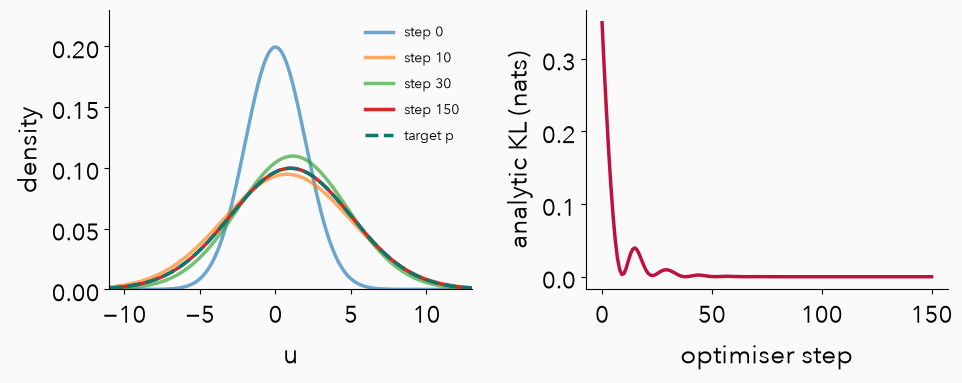

Final measured parameters: {'step': 150, 'mu': 0.9996269406912135, 'sigma': 3.999989449268585, 'kl': 4.356121350359381e-09}


In [11]:
mu = torch.nn.Parameter(torch.tensor(0.))
rho = torch.nn.Parameter(torch.tensor(math.log(2.)))
opt = torch.optim.Adam([mu, rho], lr=.08)
normal_trace = []
for step in range(151):
    q = dist.Normal(mu, rho.exp())
    loss = dist.kl_divergence(q,p)
    normal_trace.append(dict(step=step, mu=number(mu), sigma=number(rho.exp()), kl=number(loss)))
    if step == 150: break
    opt.zero_grad()
    loss.backward()
    opt.step()
assert normal_trace[-1]["kl"] < 1e-6
assert all(row["sigma"] > 0 for row in normal_trace)
fixtures["normal"]["training"] = dict(method="Adam on analytic KL", lr=.08, steps=150,
    parameterisation="sigma=exp(rho)", trace=normal_trace)
fig, axes = plt.subplots(1,2,figsize=(10,4.2))
for step in [0,10,30,150]:
    row = normal_trace[step]
    q = dist.Normal(row["mu"],row["sigma"])
    axes[0].plot(u,q.log_prob(u).exp(),label=f"step {step}",alpha=.65 if step<150 else 1)
axes[0].plot(u,p.log_prob(u).exp(),color=C["p"],ls="--",label="target p")
axes[0].set(xlim=(-11,13),ylim=(0,.23),xlabel="u",ylabel="density")
axes[0].legend(fontsize=10,frameon=False)
axes[1].plot([r["step"] for r in normal_trace],[r["kl"] for r in normal_trace],color=C["loss"])
axes[1].set(xlabel="optimiser step",ylabel="analytic KL (nats)")
savefig("gaussian-fit")
print("Final measured parameters:", normal_trace[-1])

### Watch the optimiser: from $\mathcal N(4,0.5^2)$ to $p$

The same loop, started far away, recorded at every step for the slide animation. The centre moves first; the width catches up.

In [12]:
m_o = torch.nn.Parameter(torch.tensor(4.)); rho_o = torch.nn.Parameter(torch.tensor(math.log(.5)))
opt_o = torch.optim.Adam([m_o, rho_o], lr=.05); olive = []
for step in range(201):
    loss = dist.kl_divergence(dist.Normal(m_o, rho_o.exp()), p)
    olive.append([step, number(m_o), number(rho_o.exp()), number(loss)])
    if step == 200:
        break
    opt_o.zero_grad(); loss.backward(); opt_o.step()
fixtures["story"]["olive"] = dict(start=[4., .5], lr=.05, steps=200, frames=olive)
print("start", olive[0], "· step 100", olive[100], "· end", olive[-1])

start [0, 4.0, 0.5, 1.8685040416798357] · step 100 [100, 1.05659938875126, 4.019875455515793, 0.00012475795465684454] · end [200, 1.000211262263649, 4.000164461894312, 3.0852009885032404e-09]


### Two dimensions: a diagonal $q$ cannot tilt

Target: unit variances and correlation $\rho=0.9$. A $q$ with independent coordinates (diagonal covariance) must fit inside the tilted ellipse. Under $\mathrm{KL}(q\|p)$ its best widths are the target's **conditional** widths $\sqrt{1-\rho^2}$, not the marginal widths 1. A full covariance, $\Sigma=LL^\top$ with lower-triangular $L$, matches exactly.

In [13]:
rho_2d = .9
p2d = dist.MultivariateNormal(torch.zeros(2), torch.tensor([[1., rho_2d], [rho_2d, 1.]]))
def fit_2d(full, steps=1500):
    mean = torch.nn.Parameter(torch.tensor([.5, -.5]))
    raw = torch.nn.Parameter(torch.zeros(3 if full else 2))
    opt = torch.optim.Adam([mean, raw], lr=.05)
    for _ in range(steps):
        if full:
            L = torch.stack([torch.stack([raw[0].exp(), torch.tensor(0.)]),
                             torch.stack([raw[1], raw[2].exp()])])
        else:
            L = torch.diag(raw.exp())
        q = dist.MultivariateNormal(mean, scale_tril=L)
        loss = dist.kl_divergence(q, p2d)
        opt.zero_grad(); loss.backward(); opt.step()
    return q, number(loss)
q_diag, kl_diag = fit_2d(False)
q_full, kl_full = fit_2d(True)
analytic_sd = math.sqrt(1 - rho_2d ** 2)
analytic_kl = .5 * (math.log(1 - rho_2d ** 2) - 2 * math.log(1 - rho_2d ** 2))
diag_sd = q_diag.covariance_matrix.diagonal().sqrt().tolist()
assert max(abs(v - analytic_sd) for v in diag_sd) < 2e-3 and abs(kl_diag - analytic_kl) < 1e-4 and kl_full < 1e-4
fixtures["story"]["twod"] = dict(rho=rho_2d, diag_sd=diag_sd, diag_kl=kl_diag, full_kl=kl_full,
    analytic_sd=analytic_sd, analytic_kl=analytic_kl)
print(f"diagonal q: widths {diag_sd[0]:.4f}, {diag_sd[1]:.4f} (analytic {analytic_sd:.4f}), KL {kl_diag:.4f} "
      f"(analytic {analytic_kl:.4f}); full q: KL {kl_full:.2e}")

diagonal q: widths 0.4359, 0.4359 (analytic 0.4359), KL 0.8304 (analytic 0.8304); full q: KL 0.00e+00


## 4. No formula: estimate the KL by sampling

Use the original PML mixture:

$$p(u)=0.5\,\mathcal N(u;-0.2,0.4^2)+0.5\,\mathcal N(u;1,0.5^2).$$

Compare $\mathcal N(3,1^2)$ and $\mathcal N(3,4.5^2)$. An unsupported library pair is a missing implementation, not a proof that the KL is undefined.

No KL(p || q) is implemented for p type Normal and q type MixtureSameFamily


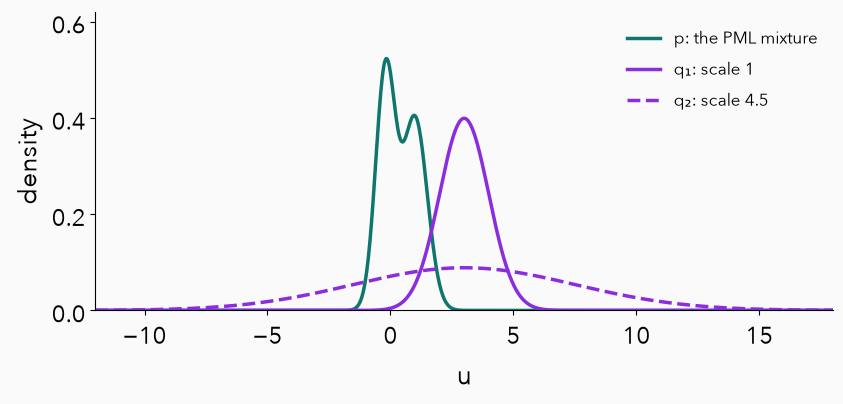

In [14]:
mixture = dist.MixtureSameFamily(
    dist.Categorical(probs=torch.tensor([.5,.5])),
    dist.Normal(torch.tensor([-.2,1.]), torch.tensor([.4,.5])))
mix_q1, mix_q2 = dist.Normal(3.,1.), dist.Normal(3.,4.5)
try:
    dist.kl_divergence(mix_q1,mixture)
    unsupported = "This runtime implements the pair."
except NotImplementedError as exc:
    unsupported = str(exc)
print(unsupported)
xx = torch.linspace(-12,18,901)
fig, ax = plt.subplots(figsize=(8.8,4.4))
ax.plot(xx,mixture.log_prob(xx).exp(),color=C["p"],label="p: the PML mixture")
ax.plot(xx,mix_q1.log_prob(xx).exp(),color=C["q"],label="q₁: scale 1")
ax.plot(xx,mix_q2.log_prob(xx).exp(),color=C["q"],ls="--",label="q₂: scale 4.5")
ax.set(xlim=(-12,18),ylim=(0,.62),xlabel="u",ylabel="density")
ax.legend(frameon=False,fontsize=12)
savefig("mixture-candidates")

Draw $u_1,\dots,u_S$ from **q**, evaluate the log ratio at each draw, then average over the sample dimension:

$$\widehat{\mathrm{KL}}_S=\frac1S\sum_{i=1}^S[\log q(u_i)-\log p(u_i)].$$

This is a Monte Carlo estimate. Validate the estimator on a known Gaussian case before using it for the mixture.

In [15]:
def mc_kl(q,p,samples,seed):
    torch.manual_seed(seed)
    draws=q.sample((samples,))
    terms=q.log_prob(draws)-p.log_prob(draws)
    return terms.mean(), terms.std(unbiased=True)/math.sqrt(samples)

mix_results=[]
for i,q in enumerate([mix_q1,mix_q2],1):
    value,se=mc_kl(q,mixture,100_000,401+i)
    # Independent numerical integral, using a wide q-dependent domain.
    grid=torch.linspace(number(q.loc-12*q.scale),number(q.loc+12*q.scale),200_001)
    integrand=q.log_prob(grid).exp()*(q.log_prob(grid)-mixture.log_prob(grid))
    numerical=torch.trapezoid(integrand,grid)
    assert abs(number(value-numerical))<5*number(se)
    mix_results.append(dict(id=f"q{i}",mu=3.,sigma=number(q.scale),mc=number(value),
        standard_error=number(se),samples=100_000,seed=401+i,quadrature=number(numerical)))
    print(f"q{i}: MC estimate {value:.5f} ± {se:.5f} (one standard error); numerical integral {numerical:.5f}")
fixtures["mixture"]={"weights":[.5,.5],"means":[-.2,1.],"scales":[.4,.5],
                     "unsupported_message":unsupported,"candidates":mix_results}

q1: MC estimate 9.54484 ± 0.02625 (one standard error); numerical integral 9.48902
q2: MC estimate 45.02336 ± 0.21184 (one standard error); numerical integral 45.15153


### Live demo 2 · estimation and gradient inspection, about 3 minutes

Keep p and q₂ fixed. Vary only the number of draws and the seed. The exact KL is unchanged. Larger S reduces estimator variance; individual estimates need not move monotonically towards the answer.

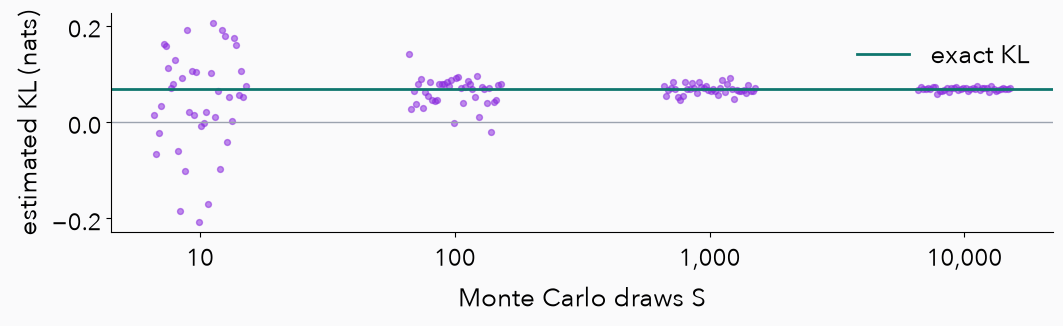

[(10, 0.10428), (100, 0.02956), (1000, 0.01022), (10000, 0.00335)]


In [16]:
repeats=[]
for size in [10,100,1000,10000]:
    vals=[number(mc_kl(q2,p,size,1000+j)[0]) for j in range(40)]
    repeats.append(dict(samples=size,seeds=list(range(1000,1040)),estimates=vals,
                        empirical_mean=float(np.mean(vals)),empirical_std=float(np.std(vals,ddof=1))))
fig,ax=plt.subplots(figsize=(11,3.6))
for i,row in enumerate(repeats):
    jitter=np.linspace(-.18,.18,len(row["estimates"]))
    ax.scatter(i+jitter,row["estimates"],s=18,color=C["q"],alpha=.55)
ax.axhline(number(dist.kl_divergence(q2,p)),color=C["p"],label="exact KL",lw=2)
ax.axhline(0,color="#9CA3AF",lw=1)
ax.set(xticks=range(4),xticklabels=["10","100","1,000","10,000"],
       xlabel="Monte Carlo draws S",ylabel="estimated KL (nats)")
ax.legend(frameon=False,fontsize=19)
savefig("mc-variability")
fixtures["monte_carlo"]={"q":"q2","exact_kl":number(dist.kl_divergence(q2,p)),
                         "repeats":repeats}
print([(r["samples"],round(r["empirical_std"],5)) for r in repeats])

A finite-sample KL estimate can be negative even though the true KL is nonnegative. The next cell deliberately finds the first seed giving a negative **five-draw estimate**, as a counterexample. This seed selection is not a performance comparison.

In [17]:
negative_seed=next(s for s in range(1000) if number(mc_kl(q2,p,5,s)[0])<0)
torch.manual_seed(negative_seed)
draws=q2.sample((5,))
terms=q2.log_prob(draws)-p.log_prob(draws)
fixtures["monte_carlo"]["negative_example"]=dict(seed=negative_seed,samples=5,
    selection="first seed in 0..999 giving a negative estimate; intentional counterexample",
    draws=draws.tolist(),log_q=q2.log_prob(draws).tolist(),log_p=p.log_prob(draws).tolist(),
    terms=terms.tolist(),estimate=number(terms.mean()))
print("Selected seed:",negative_seed)
for x,lq,lp,t in zip(draws,q2.log_prob(draws),p.log_prob(draws),terms):
    print(f"u={x: .4f}  log q={lq: .4f}  log p={lp: .4f}  difference={t: .4f}")
print("Five-draw estimate:",number(terms.mean()),"· exact KL:",number(dist.kl_divergence(q2,p)))

Selected seed: 0
u= 5.6230  log q=-3.2049  log p=-2.9731  difference=-0.2318
u= 0.1197  log q=-2.0606  log p=-2.3294  difference= 0.2688
u=-5.5364  log q=-4.3911  log p=-3.6404  difference=-0.7508
u= 2.7053  log q=-2.1791  log p=-2.3961  difference= 0.2170
u=-2.2536  log q=-2.6056  log p=-2.6360  difference= 0.0304
Five-draw estimate: -0.09325773189856931 · exact KL: 0.0689320724517809


## 5. Gradients through random draws

First inspect the sample itself. `Normal.sample()` returns a draw without the pathwise gradient connection to the Normal's parameters. Asking that scalar draw for a gradient fails.

However, a larger loss containing `q.log_prob(draw)` can still produce a gradient through the explicit log-density parameters. **A gradient tensor alone does not prove that the missing sample path was handled correctly.**

In [18]:
torch.manual_seed(12)
mu=torch.tensor(0.,requires_grad=True)
sigma=torch.tensor(2.,requires_grad=True)
q=dist.Normal(mu,sigma)
draw=q.sample()
try:
    draw.backward()
    sample_error="No error"
except RuntimeError as exc:
    sample_error=str(exc)
print("sample.requires_grad:",draw.requires_grad)
print("sample.backward():",sample_error)

# Same chosen noise lets us compare estimators without confounding them with new draws.
torch.manual_seed(13)
eps=torch.randn(50_000)
detached=(mu+sigma*eps).detach()
wrong_loss=(q.log_prob(detached)-p.log_prob(detached)).mean()
wrong_grads=torch.autograd.grad(wrong_loss,(mu,sigma))
correct_draw=mu+sigma*eps
path_loss=(q.log_prob(correct_draw)-p.log_prob(correct_draw)).mean()
path_grads=torch.autograd.grad(path_loss,(mu,sigma))
exact_grads=((0.-1.)/16,2./16-1./2)
fixtures["gradients"]={"sample_seed":12,"sample_requires_grad":draw.requires_grad,
    "sample_backward_error":sample_error,"comparison_seed":13,"samples":50000,
    "detached_sample_grads":[number(v) for v in wrong_grads],
    "pathwise_grads":[number(v) for v in path_grads],"analytic_grads":list(exact_grads)}
print("Naive detached-sample grads:",[number(v) for v in wrong_grads])
print("Pathwise grads:",[number(v) for v in path_grads])
print("Analytic reference:",exact_grads)

sample.requires_grad: False
sample.backward(): element 0 of tensors does not require grad and does not have a grad_fn
Naive detached-sample grads: [0.001281465829292653, -0.0002523191477337705]
Pathwise grads: [-0.06217963354267684, -0.375223263015595]
Analytic reference: (-0.0625, -0.375)


The naive detached-sample derivative above omits the effect of changing q's sampling distribution. A properly constructed **score-function estimator** is another valid route; we are not claiming that all useful gradients require reparameterisation.

### Put the randomness outside the parameters

$$\epsilon\sim\mathcal N(0,1),\quad u=\mu+\sigma\epsilon,\quad
\frac{\partial u}{\partial\mu}=1,\quad
\frac{\partial u}{\partial\sigma}=\epsilon.$$

Hold the same $\epsilon$ fixed while checking derivatives. Normal training uses fresh noise. The chosen scalar $\epsilon=-0.75$ below makes the arithmetic inspectable; it is not presented as a random sample.

In [19]:
mu=torch.tensor(0.,requires_grad=True)
sigma=torch.tensor(2.,requires_grad=True)
eps_chosen=torch.tensor(-.75)
draw=mu+sigma*eps_chosen
du=torch.autograd.grad(draw,(mu,sigma),retain_graph=True)
scalar_loss=(draw-1).square()
dL=torch.autograd.grad(scalar_loss,(mu,sigma))
fixtures["gradients"]["scalar"]=dict(mu=0.,sigma=2.,epsilon=-.75,u=number(draw),
    loss=number(scalar_loss),du_dmu=number(du[0]),du_dsigma=number(du[1]),
    dloss_dmu=number(dL[0]),dloss_dsigma=number(dL[1]))
print(fixtures["gradients"]["scalar"])

{'mu': 0.0, 'sigma': 2.0, 'epsilon': -0.75, 'u': -1.5, 'loss': 6.25, 'du_dmu': 1.0, 'du_dsigma': -0.75, 'dloss_dmu': -5.0, 'dloss_dsigma': 3.75}


`Normal.rsample()` uses a differentiable draw. To check the derivative numerically, reuse one fixed noise array in both finite-difference evaluations.

In [20]:
torch.manual_seed(88)
eps_fixed=torch.randn(2048)
def fixed_noise_loss(mu_value,sigma_value):
    q=dist.Normal(mu_value,sigma_value)
    x=mu_value+sigma_value*eps_fixed
    return (q.log_prob(x)-p.log_prob(x)).mean()
mu=torch.tensor(0.,requires_grad=True)
sigma=torch.tensor(2.,requires_grad=True)
g=torch.autograd.grad(fixed_noise_loss(mu,sigma),(mu,sigma))
h=1e-5
fd_mu=(fixed_noise_loss(mu.detach()+h,sigma.detach())-fixed_noise_loss(mu.detach()-h,sigma.detach()))/(2*h)
fd_sigma=(fixed_noise_loss(mu.detach(),sigma.detach()+h)-fixed_noise_loss(mu.detach(),sigma.detach()-h))/(2*h)
assert abs(number(g[0]-fd_mu))<1e-8
assert abs(number(g[1]-fd_sigma))<1e-8
torch.manual_seed(88)
rs=dist.Normal(mu,sigma).rsample((2048,))
assert torch.allclose(rs,mu+sigma*eps_fixed)
fixtures["gradients"]["finite_difference"]=dict(seed=88,samples=2048,h=h,
    autograd=[number(v) for v in g],finite_difference=[number(fd_mu),number(fd_sigma)])
print(fixtures["gradients"]["finite_difference"])

{'seed': 88, 'samples': 2048, 'h': 1e-05, 'autograd': [-0.06246599500273631, -0.3722226142944757], 'finite_difference': [-0.06246599500159266, -0.37222261430047693]}


### Optimise the Monte Carlo KL: `sample()` versus `rsample()`

Fit a Gaussian to the PML mixture starting from $\mathcal N(6,0.1^2)$, with 5,000 draws per step and plain gradient descent. With `sample()` the code runs, but the draws carry no path back to $\mu$ and $\sigma$: the surviving gradient averages to zero and $q$ barely moves. (Adam rescales its steps, so with Adam the stuck run wanders aimlessly instead; it still never fits.) With `rsample()` the same loop fits the mixture.

sample(): final N(6.076, 0.097^2), MC KL 53.372, quadrature KL 53.380
rsample(): final N(0.429, 0.720^2), MC KL 0.061, quadrature KL 0.056


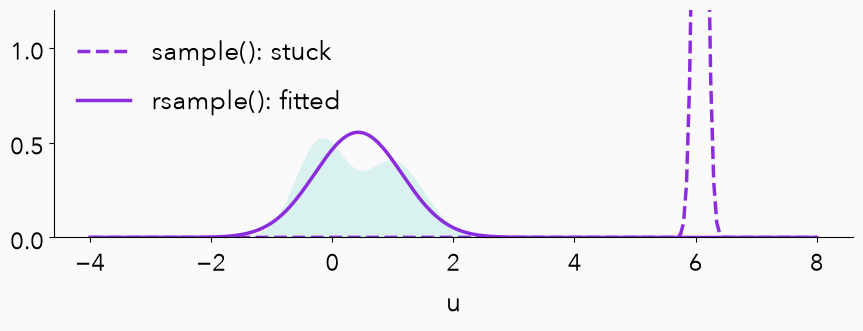

In [21]:
def mixture_kl_quadrature(q):
    g = torch.linspace(-10, 12, 20_001)
    lq = q.log_prob(g)
    return number(torch.trapezoid(lq.exp() * (lq - mixture.log_prob(g)), g))
def fit_mixture(use_rsample, steps=400, draws=5000, seed=4004, dense=120, every=5):
    torch.manual_seed(seed)
    m = torch.nn.Parameter(torch.tensor(6.)); rho = torch.nn.Parameter(torch.tensor(math.log(.1)))
    opt = torch.optim.SGD([m, rho], lr=.05); frames = []
    for step in range(steps + 1):
        q = dist.Normal(m, rho.exp())
        u_s = q.rsample((draws,)) if use_rsample else q.sample((draws,))
        loss = (q.log_prob(u_s) - mixture.log_prob(u_s)).mean()
        if step <= dense or step % every == 0:  # dense frames while q moves, for the slide animation
            frames.append([step, number(m), number(rho.exp()), number(loss),
                           mixture_kl_quadrature(dist.Normal(m.detach(), rho.detach().exp()))])
        if step == steps:
            break
        opt.zero_grad(); loss.backward(); opt.step()
    return frames
mix_rsample = fit_mixture(True)
mix_sample = fit_mixture(False)
x_mix = torch.linspace(-4, 8, 241)
fixtures["story"]["mixfit"] = dict(start=[6., .1], optimiser="SGD", lr=.05, steps=400, draws=5000, seed=4004,
    rsample=mix_rsample, sample=mix_sample, x=x_mix.tolist(), p=mixture.log_prob(x_mix).exp().tolist())
for name, frames in [("sample()", mix_sample), ("rsample()", mix_rsample)]:
    _, m_, s_, est, exact = frames[-1]
    print(f"{name}: final N({m_:.3f}, {s_:.3f}^2), MC KL {est:.3f}, quadrature KL {exact:.3f}")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(x_mix, 0, mixture.log_prob(x_mix).exp(), color="#D9F2EF")
for frames, style, label in [(mix_sample, "--", "sample(): stuck"), (mix_rsample, "-", "rsample(): fitted")]:
    _, m_, s_, _, _ = frames[-1]
    ax.plot(x_mix, dist.Normal(m_, s_).log_prob(x_mix).exp(), color=C["q"], ls=style, label=label)
ax.set(ylim=(0, 1.2), xlabel="u")
ax.legend(frameon=False)
savefig("mixture-fit")

## 6. The real target: a posterior we cannot write down

For a fixed model and observed dataset:

$$\begin{aligned}
\mathrm{KL}(q_\psi(u)\|p(u\mid\mathcal D))
&=\mathbb E_q[\log q_\psi(u)-\log p(u\mid\mathcal D)]\\
&=\mathbb E_q[\log q_\psi(u)-\log p(\mathcal D,u)+\log p(\mathcal D)]\\
&=\mathbb E_q[\log q_\psi(u)-\log p(\mathcal D,u)]+\log p(\mathcal D).
\end{aligned}$$

The second line uses Bayes' rule and the log quotient. The third uses linearity: the evidence does not vary with u or ψ for this fixed model.

Rearranging:

$$\log p(\mathcal D)=
\underbrace{\mathbb E_q[\log p(\mathcal D,u)-\log q_\psi(u)]}_{\mathrm{ELBO}(q_\psi)}
+\mathrm{KL}(q_\psi\|p(u\mid\mathcal D)).$$

Maximise the ELBO, or minimise its negative. We can evaluate the **joint** without the evidence normaliser. Estimating the expectation can still require Monte Carlo. A finite-sample ELBO estimate need not lie below the evidence on every draw; the exact expectation is the lower bound.

## 7. A check with an answer key: the Beta coin

Use a Beta(5,3) prior and **one ordered sequence** with 17 heads and 13 tails. Any order with these counts has the same sequence likelihood:

$$p(\mathcal D\mid r)=r^{17}(1-r)^{13}.$$

There is no binomial coefficient in this convention. The known posterior Beta(22,16) and known evidence are for **validation**, not inputs to the optimiser.

In [22]:
tosses="HHTHTHTHHHTTHTHHTHTTHHHTTHTHTH"
assert len(tosses)==30 and tosses.count("H")==17 and tosses.count("T")==13
prior=dist.Beta(torch.tensor(5.),torch.tensor(3.))
posterior=dist.Beta(torch.tensor(22.),torch.tensor(16.))
heads,tails=17,13
def log_joint(r):
    return prior.log_prob(r)+heads*torch.log(r)+tails*torch.log1p(-r)
def log_beta(a,b):
    return torch.lgamma(a)+torch.lgamma(b)-torch.lgamma(a+b)
log_evidence=log_beta(torch.tensor(22.),torch.tensor(16.))-log_beta(torch.tensor(5.),torch.tensor(3.))
def direct_beta_elbo(a,b):
    a,b=torch.as_tensor(a),torch.as_tensor(b)
    mean_log_r=torch.digamma(a)-torch.digamma(a+b)
    mean_log_1mr=torch.digamma(b)-torch.digamma(a+b)
    expected_likelihood=heads*mean_log_r+tails*mean_log_1mr
    expected_prior=4*mean_log_r+2*mean_log_1mr-log_beta(torch.tensor(5.),torch.tensor(3.))
    expected_log_q=(a-1)*mean_log_r+(b-1)*mean_log_1mr-log_beta(a,b)
    return expected_likelihood+expected_prior-expected_log_q
coin_candidates=[]
for a,b in [(10.,10.),(30.,20.),(22.,16.)]:
    q=dist.Beta(torch.tensor(a),torch.tensor(b))
    elbo=direct_beta_elbo(a,b)
    gap=dist.kl_divergence(q,posterior)
    assert abs(number(elbo+gap-log_evidence))<1e-10
    coin_candidates.append(dict(a=a,b=b,elbo=number(elbo),posterior_kl=number(gap)))
    print(f"Beta({a:g},{b:g}): ELBO={elbo:.9f}; posterior KL={gap:.9f}; sum={elbo+gap:.9f}")
fixtures["coin"]={"ordered_sequence":tosses,"heads":heads,"tails":tails,
    "prior":[5,3],"posterior":[22,16],"log_evidence":number(log_evidence),
    "candidates":coin_candidates,"convention":"ordered sequence; no binomial coefficient"}

Beta(10,10): ELBO=-22.020154134; posterior KL=0.622912312; sum=-21.397241822
Beta(30,20): ELBO=-21.448585391; posterior KL=0.051343569; sum=-21.397241822
Beta(22,16): ELBO=-21.397241822; posterior KL=0.000000000; sum=-21.397241822


### Live demo 3 · joint-only optimisation, about 3–4 minutes

Let $q_\psi(r)=\mathrm{Beta}(a,b)$ with $a=\exp(\psi_a)$ and $b=\exp(\psi_b)$. Both shape parameters remain positive.

For S scalar draws, `log_joint(r)` and `q.log_prob(r)` each have shape `[S]`. Their difference is averaged **once over S**. The 30 observations are already summed in the log likelihood. We do not multiply the entropy by 30 or sum the sample dimension before averaging.

`Beta.rsample()` is differentiable, but it is not the Gaussian formula $\mu+\sigma\epsilon$. PyTorch supplies an implicit reparameterisation gradient.

In [23]:
torch.manual_seed(2401)
psi=torch.nn.Parameter(torch.log(torch.tensor([10.,10.])))
optimiser=torch.optim.Adam([psi],lr=.025)
coin_trace=[]
for step in range(601):
    a,b=psi.exp()
    q=dist.Beta(a,b)
    with torch.no_grad():
        exact_elbo=direct_beta_elbo(a,b)
        exact_gap=dist.kl_divergence(q,posterior)
        coin_trace.append(dict(step=step,a=number(a),b=number(b),
                              exact_elbo=number(exact_elbo),posterior_kl=number(exact_gap)))
    if step==600: break
    r=q.rsample((512,))
    terms=log_joint(r)-q.log_prob(r)
    assert terms.shape==(512,)
    loss=-terms.mean()
    optimiser.zero_grad()
    loss.backward()
    if step==0:
        fixtures["coin"]["first_step"]=dict(a=number(a),b=number(b),
            sampled_negative_elbo=number(loss),gradient_psi=psi.grad.tolist(),
            shape=list(terms.shape),reduction="mean over 512 independent scalar r draws")
    optimiser.step()
    coin_trace[-1]["sampled_negative_elbo"]=number(loss)
assert coin_trace[-1]["posterior_kl"]<.01
assert all(r["a"]>0 and r["b"]>0 for r in coin_trace)
fixtures["coin"]["training"]={"seed":2401,"steps":600,"samples_per_step":512,
    "learning_rate":.025,"optimiser":"Adam","parameterisation":"a,b=exp(psi)",
    "objective":"negative Monte Carlo mean of log_joint(r)-log_q(r)",
    "reference_used_by_optimiser":False,"trace":coin_trace}
print("Measured final fit:",coin_trace[-1])
print("Reference Beta(22,16) was used only for diagnostics.")

Measured final fit: {'step': 600, 'a': 22.39359918744698, 'b': 16.189260387679358, 'exact_elbo': -21.39746336078113, 'posterior_kl': 0.00022153846902073226}
Reference Beta(22,16) was used only for diagnostics.


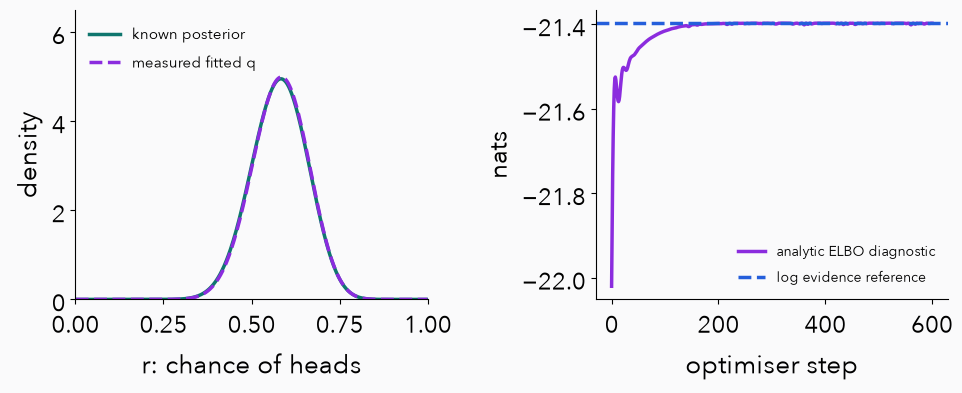

In [24]:
rr=torch.linspace(.001,.999,501)
fig,axes=plt.subplots(1,2,figsize=(10,4.3))
axes[0].plot(rr,posterior.log_prob(rr).exp(),color=C["p"],label="known posterior")
final=coin_trace[-1]
fitted=dist.Beta(final["a"],final["b"])
axes[0].plot(rr,fitted.log_prob(rr).exp(),color=C["q"],ls="--",label="measured fitted q")
axes[0].set(xlim=(0,1),ylim=(0,6.5),xlabel="r: chance of heads",ylabel="density")
axes[0].legend(frameon=False,fontsize=11)
axes[1].plot([r["step"] for r in coin_trace],[r["exact_elbo"] for r in coin_trace],
             color=C["q"],label="analytic ELBO diagnostic")
axes[1].axhline(number(log_evidence),color=C["data"],ls="--",label="log evidence reference")
axes[1].set(xlabel="optimiser step",ylabel="nats")
axes[1].legend(frameon=False,fontsize=10)
savefig("coin-fit")

### A noisy objective is not the exact bound

The next figure compares the actual stochastic objective used during training with the analytic ELBO of the same pre-update q. Training samples change at every step. Apparent one-step movement of the noisy trace is not a certificate of improvement.

The exact posterior is in the Beta family, so exact recovery is possible in principle. A restricted family, incomplete optimisation, or local optima can prevent it in other problems. A stable training loss does not prove zero posterior KL.

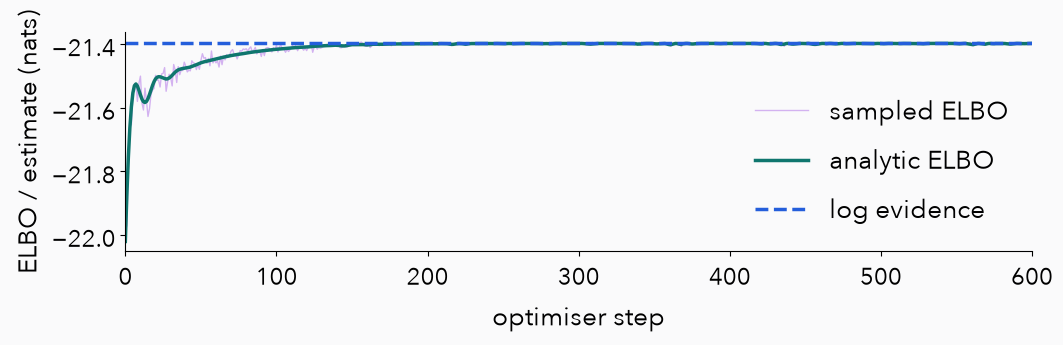

MC estimates above the exact evidence: 162


In [25]:
fig,ax=plt.subplots(figsize=(11,3.6))
steps=np.array([r["step"] for r in coin_trace[:-1]])
sampled=np.array([-r["sampled_negative_elbo"] for r in coin_trace[:-1]])
exact=np.array([r["exact_elbo"] for r in coin_trace[:-1]])
ax.plot(steps,sampled,color=C["q"],alpha=.35,lw=1,label="sampled ELBO")
ax.plot(steps,exact,color=C["p"],label="analytic ELBO")
ax.axhline(number(log_evidence),color=C["data"],ls="--",label="log evidence")
ax.set(xlim=(0,600),xlabel="optimiser step",ylabel="ELBO / estimate (nats)")
ax.legend(frameon=False,fontsize=19)
savefig("coin-noisy-objective")
fixtures["coin"]["sampled_estimates_above_evidence"]=int(np.sum(sampled>number(log_evidence)))
print("MC estimates above the exact evidence:",fixtures["coin"]["sampled_estimates_above_evidence"])

## 8. Variational inference for the tiny network

A mean-field Gaussian over the seven parameters,

$$q_\psi(\theta)=\prod_{j=1}^{7}\mathcal N(\theta_j;\mu_j,\sigma_j^2),\qquad\psi=(\mu,\rho),\ \sigma=\exp(\rho):\ 14\text{ numbers}.$$

Maximise $\mathrm{ELBO}(\psi)=\mathbb E_q[\log p(\mathcal D\mid\theta)]-\mathrm{KL}(q_\psi\,\|\,p(\theta))$. The first term is a Monte Carlo average over `rsample` draws (16 per step); the second is the closed-form Gaussian KL from Section 2, summed over the seven parameters. Five random starts; we keep the one with the highest final ELBO.

restart ELBOs [-7.18, -7.49, -7.22, -7.18, -7.3] · kept seed 0
ELBO -7.18 = E_q[log p(D|θ)] 8.10 − KL(q||prior) 15.28
log p(D) ≈ -1.43, so KL(q || posterior) ≈ 5.75 nats
predictive sd at x = −2.5, 0, 2.5: VI [0.11, 0.13, 0.11] · HMC [0.215, 0.162, 0.168]


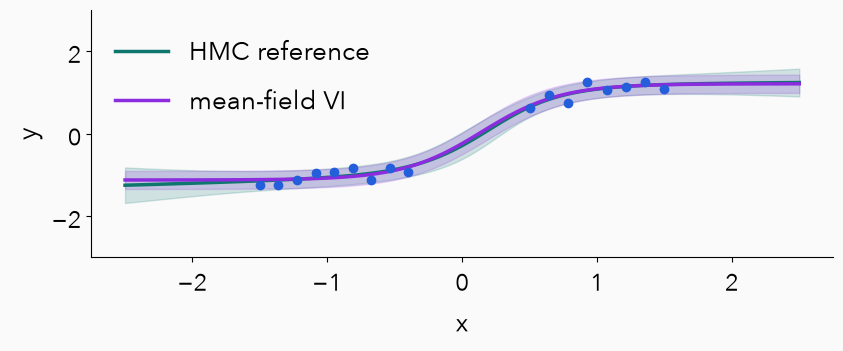

In [26]:
def fit_bnn_vi(seed, steps=4000, draws=16, lr=.02, record=False):
    torch.manual_seed(seed)
    mu = torch.nn.Parameter(.5 * torch.randn(7))
    rho = torch.nn.Parameter(torch.full((7,), math.log(.1)))
    opt_vi = torch.optim.Adam([mu, rho], lr=lr)
    eps_eval = torch.randn(2000, 7)  # fixed draws, so the recorded ELBO curve is smooth
    frames = []
    for step in range(steps + 1):
        q = dist.Normal(mu, rho.exp())
        if record and ((step <= 200 and step % 5 == 0) or step % 50 == 0):
            with torch.no_grad():
                th_eval = mu + rho.exp() * eps_eval
                F_eval = net(th_eval, x_grid)
                elbo_eval = bnn_log_lik(th_eval).mean() - dist.kl_divergence(q, theta_prior).sum()
                frames.append([step, round(number(elbo_eval), 4), [round(v, 4) for v in F_eval.mean(0).tolist()],
                               [round(v, 4) for v in (F_eval.var(0) + noise_sd ** 2).sqrt().tolist()]])
        if step == steps:
            break
        theta_s = q.rsample((draws,))
        elbo = bnn_log_lik(theta_s).mean() - dist.kl_divergence(q, theta_prior).sum()
        opt_vi.zero_grad(); (-elbo).backward(); opt_vi.step()
    q = dist.Normal(mu.detach(), rho.detach().exp())
    torch.manual_seed(20_000 + seed)
    th_final = q.sample((20_000,))
    expected_log_lik = number(bnn_log_lik(th_final).mean())
    kl_prior = number(dist.kl_divergence(q, theta_prior).sum())
    return dict(seed=seed, q=q, frames=frames, expected_log_lik=expected_log_lik, kl_prior=kl_prior,
                elbo=expected_log_lik - kl_prior)
restarts = [fit_bnn_vi(seed) for seed in range(5)]
vi_run = fit_bnn_vi(max(restarts, key=lambda r: r["elbo"])["seed"], record=True)
assert abs(vi_run["elbo"] - max(r["elbo"] for r in restarts)) < 1e-9  # same seed, same run
q_vi = vi_run["q"]
torch.manual_seed(14)
F_vi = net(q_vi.sample((4000,)), x_grid)
vi_sd = (F_vi.var(0) + noise_sd ** 2).sqrt()
assert vi_run["elbo"] < log_evidence_bnn
fixtures["story"]["bnn"]["vi"] = dict(steps=4000, draws=16, lr=.02, restart_elbos=[r["elbo"] for r in restarts],
    seed=vi_run["seed"], mu=q_vi.loc.tolist(), sigma=q_vi.scale.tolist(), elbo=vi_run["elbo"],
    expected_log_lik=vi_run["expected_log_lik"], kl_prior=vi_run["kl_prior"], gap=log_evidence_bnn - vi_run["elbo"],
    frames=vi_run["frames"], mean=F_vi.mean(0).tolist(), sd=vi_sd.tolist())
print("restart ELBOs", [round(r["elbo"], 2) for r in restarts], "· kept seed", vi_run["seed"])
print(f"ELBO {vi_run['elbo']:.2f} = E_q[log p(D|θ)] {vi_run['expected_log_lik']:.2f} − KL(q||prior) {vi_run['kl_prior']:.2f}")
print(f"log p(D) ≈ {log_evidence_bnn:.2f}, so KL(q || posterior) ≈ {log_evidence_bnn - vi_run['elbo']:.2f} nats")
print("predictive sd at x = −2.5, 0, 2.5: VI", [round(number(vi_sd[i]), 3) for i in (0, 60, 120)],
      "· HMC", [round(number(post_sd[i]), 3) for i in (0, 60, 120)])
fig, ax = plt.subplots(figsize=(8.8, 4))
for mean, sd, color, label in [(F_post.mean(0), post_sd, C["p"], "HMC reference"), (F_vi.mean(0), vi_sd, C["q"], "mean-field VI")]:
    ax.fill_between(x_grid, mean - 2 * sd, mean + 2 * sd, color=color, alpha=.18)
    ax.plot(x_grid, mean, color=color, label=label)
ax.scatter(x_train, y_train, color=C["data"], zorder=3)
ax.set(xlabel="x", ylabel="y", ylim=(-3, 3)); ax.legend(frameon=False)
savefig("bnn-vi-vs-hmc")

## 9. Retrieve the method

Before revealing the answers, answer these in your own words:

1. For KL(q‖p), where do the samples come from?
2. What changes during VI: data, model, posterior, variational parameters, or all of them?
3. Why can we optimise without knowing the evidence?
4. Does an ELBO estimate above the evidence disprove the lower-bound identity?
5. Does a high or stable ELBO prove that q equals the posterior?

**Answers.** Draw from q. In the fixed-model inference problem, update ψ; data, model and exact posterior stay fixed. The evidence is constant in ψ. A finite-sample estimate is not the exact expectation. Improvement is not an exact-recovery certificate.

**Transfer:** for an image model $p_\theta(x,z)$ with fixed θ, specify $q_\psi(z)$ and maximise $\mathbb E_q[\log p_\theta(x,z)-\log q_\psi(z)]$. Lecture 3 will learn model parameters and share an encoder across observations.

## Optional depth: an independent integral check

The scalar Beta example also permits numerical integration. This is an approximate quadrature check, labelled separately from the analytic formula. At endpoints the integrands have zero limits for these chosen shape parameters.

In [27]:
grid=torch.linspace(0,1,100001)
interior=grid[1:-1]
quad_checks=[]
for row in coin_candidates:
    q=dist.Beta(row["a"],row["b"])
    density=q.log_prob(interior).exp()
    integrand=density*(log_joint(interior)-q.log_prob(interior))
    padded=torch.cat([torch.zeros(1),integrand,torch.zeros(1)])
    numerical=torch.trapezoid(padded,grid)
    error=abs(number(numerical)-row["elbo"])
    assert error<1e-8
    quad_checks.append(dict(a=row["a"],b=row["b"],numerical_elbo=number(numerical),error=error))
fixtures["checks"]={"coin_quadrature":quad_checks,
    "normal_analytic_vs_library":True,"normal_gradient_finite_difference":True,
    "positive_scales_and_shapes":True,"fixed_noise_gradient_check":True,
    "coin_direct_elbo_identity":True,"coin_training_final_gap":coin_trace[-1]["posterior_kl"]}
print(quad_checks)

[{'a': 10.0, 'b': 10.0, 'numerical_elbo': -22.020154134036773, 'error': 3.552713678800501e-14}, {'a': 30.0, 'b': 20.0, 'numerical_elbo': -21.448585391137854, 'error': 8.526512829121202e-14}, {'a': 22.0, 'b': 16.0, 'numerical_elbo': -21.397241822312157, 'error': 4.973799150320701e-14}]


## Optional depth: count data versus an ordered sequence

If the observation were only the count “17 heads out of 30”, the likelihood would include $\binom{30}{17}$. This constant would add to both log evidence and ELBO. The posterior and the posterior-KL gap would be unchanged. We have used the ordered-sequence convention consistently.

In [28]:
log_choose=math.lgamma(31)-math.lgamma(18)-math.lgamma(14)
print("Log binomial coefficient:",log_choose)
print("Count-data log evidence:",number(log_evidence)+log_choose)
print("Ordered-sequence log evidence:",number(log_evidence))
fixtures["coin"]["count_convention_comparison"]={"log_binomial_coefficient":log_choose,
    "count_log_evidence":number(log_evidence)+log_choose}
fixtures["plots"]={
    "normal":{"x":u.tolist(),"p":p.log_prob(u).exp().tolist(),
        "q1":q1.log_prob(u).exp().tolist(),"q2":q2.log_prob(u).exp().tolist(),
        "updated":dist.Normal(.25,2.).log_prob(u).exp().tolist(),
        "snapshots":{str(s):dist.Normal(normal_trace[s]["mu"],normal_trace[s]["sigma"]).log_prob(u).exp().tolist()
                     for s in [0,10,30,150]}},
    "mixture":{"x":xx.tolist(),"p":mixture.log_prob(xx).exp().tolist(),
        "q1":mix_q1.log_prob(xx).exp().tolist(),"q2":mix_q2.log_prob(xx).exp().tolist()},
    "coin":{"x":rr.tolist(),"prior":prior.log_prob(rr).exp().tolist(),
        "posterior":posterior.log_prob(rr).exp().tolist(),
        "candidates":[dist.Beta(row["a"],row["b"]).log_prob(rr).exp().tolist() for row in coin_candidates],
        "snapshots":{str(s):dist.Beta(coin_trace[s]["a"],coin_trace[s]["b"]).log_prob(rr).exp().tolist()
                     for s in [0,20,100,600]}}
}
(OUT/"data"/"science.json").write_text(json.dumps(fixtures,indent=2,allow_nan=False)+"\n")
(OUT/"qa"/"notebook-checks.json").write_text(json.dumps({
    "status":"passed","runtime":fixtures["provenance"],"checks":fixtures["checks"],
    "executed_code_cells":"all cells in saved notebook",
    "training":"toy CPU optimisation; measured trajectories, not schematic",
},indent=2,allow_nan=False)+"\n")
print("Saved full-precision fixtures and verification report.")

Log binomial coefficient: 18.600999045569846
Count-data log evidence: -2.7962427767422575
Ordered-sequence log evidence: -21.397241822312104
Saved full-precision fixtures and verification report.


## Sources and adaptation

- Nipun Batra, [PML 2023 VI notebook](https://github.com/nipunbatra/pml-teaching/blob/master/notebooks/variational-inference.ipynb): Gaussian, mixture, reparameterisation and coin teaching sequence.
- [PyTorch distribution documentation](https://pytorch.org/docs/stable/distributions.html): distribution parameters, `sample`, `rsample` and KL API.
- Figurnov, Mohamed and Mnih, [Implicit Reparameterization Gradients](https://arxiv.org/abs/1805.08498): differentiable sampling beyond the location–scale Gaussian form.

This is a new standalone implementation. It removes hidden training helpers, stale computation-graph references and unsafe unconstrained positive parameters from the historical notebook. Numerical results here come from the saved execution, with the configurations above.